In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import pandas as pd
import numpy as np


In [4]:
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense

from skimage.io import imread
from skimage.transform import resize

In [5]:
os.listdir('/content/drive/MyDrive/Mask data (1)')

['Mask_train', 'Mask_test']

In [6]:
os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_train')

['without_mask', 'with_mask']

In [7]:
os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_test')

['without_mask', 'with_mask']

In [8]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_test/with_mask'))

53

In [9]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_test/without_mask'))

53

In [10]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_train/with_mask'))

690

In [11]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_train/without_mask'))

686

In [12]:
xtrain = []
ytrain = []

In [13]:
datadir = '/content/drive/MyDrive/Mask data (1)/Mask_train'

In [14]:
categories = ['without_mask', 'with_mask']

In [15]:
for i in categories:
  print(i)
  path = os.path.join(datadir,i)

  for img in os.listdir(path):
    img_path = os.path.join(path,img)

    img_read = imread(img_path)
    img_res = resize(img_read,(150,150,3))

    if img_res.shape != (150,150,3):
      print(img, img_res.shape)

    xtrain.append(img_res)
    ytrain.append(categories.index(i))



without_mask
with_mask


In [16]:
print(img_read.shape)

(428, 320, 3)


In [17]:
print(img, img_read.shape)

augmented_image_118.jpg (428, 320, 3)


In [18]:
# testing

xtest = []
ytest = []

datadir1 = '/content/drive/MyDrive/Mask data (1)/Mask_test'
categories1 =  ['without_mask', 'with_mask']

In [19]:
for j in categories1:
  print(j)
  path1 = os.path.join(datadir1,j)

  for imgs in os.listdir(path1):
    imgs_path = os.path.join(path1,imgs)

    img2 = imread(imgs_path)
    img2_res = resize(img2,(150,150,3))

    xtest.append(img2_res)
    ytest.append(categories1.index(j))

without_mask
with_mask


In [20]:
xtrain = np.array(xtrain)
ytrain = np.array(ytrain)
xtest = np.array(xtest)
ytest = np.array(ytest)

In [21]:
# from collections import Counter

# shapes = Counter([img.shape for img in xtest])

# print(shapes)

In [22]:
model = Sequential()

In [23]:
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(150,150,3)))
model.add(Conv2D(64,(3,3),activation='relu',input_shape=(150,150,3)))
model.add(Conv2D(128,(3,3),activation='relu',input_shape=(150,150,3)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
model.add(MaxPool2D(2,2))

In [25]:
model.add(Flatten())

In [26]:
model.add(Dense(50,activation='relu'))
model.add(Dense(20,activation='relu'))
model.add(Dense(2,activation='softmax'))

In [27]:
model.compile(optimizer='adam',
              loss = 'sparse_categorical_crossentropy',
              metrics = ['accuracy'])

In [29]:
model.fit(xtrain,ytrain,epochs=10 , batch_size = 40)

Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 411s 12s/step - accuracy: 0.7703 - loss: 0.4273
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 434s 11s/step - accuracy: 0.9680 - loss: 0.0946
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 442s 11s/step - accuracy: 0.9680 - loss: 0.0915
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 407s 12s/step - accuracy: 0.9680 - loss: 0.0840
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 436s 11s/step - accuracy: 0.9811 - loss: 0.0500
Epoch 6/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 403s 11s/step - accuracy: 0.9891 - loss: 0.0308
Epoch 7/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 403s 11s/step - accuracy: 0.9935 - loss: 0.0264
Epoch 8/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 404s 12s/step - accuracy: 0.9956 - loss: 0.0149
Epoch 9/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 403s 12s/step - accuracy: 0.9985 - loss: 0.0063
Epoch 10/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 403s 12s/step - accuracy: 0.9935 - loss: 0.0222


In [39]:
# img = '/content/drive/MyDrive/Mask data (1)/Mask_test/with_mask/103-with-mask.jpg'
# img_read = imread(img)
# img_read

In [41]:
# res = resize(img_read,(1,150,150,3))
# pred = model.predict(res)
# pred

In [43]:
# predicted_class = np.argmax(pred,axis=1)
# print(predicted_class)

array([[[184,  78, 116],
        [184,  78, 116],
        [184,  78, 116],
        ...,
        [193,  81, 121],
        [193,  81, 121],
        [193,  81, 119]],

       [[185,  79, 117],
        [185,  79, 117],
        [185,  79, 117],
        ...,
        [193,  81, 121],
        [193,  81, 121],
        [193,  81, 119]],

       [[185,  79, 117],
        [185,  79, 117],
        [185,  79, 117],
        ...,
        [193,  81, 121],
        [193,  81, 121],
        [193,  81, 119]],

       ...,

       [[222, 103, 131],
        [222, 103, 131],
        [225, 102, 131],
        ...,
        [ 15,  13,  14],
        [ 15,  13,  14],
        [ 16,  14,  17]],

       [[222, 103, 131],
        [222, 103, 131],
        [225, 102, 131],
        ...,
        [ 15,  13,  14],
        [ 15,  13,  14],
        [ 16,  14,  17]],

       [[222, 103, 131],
        [222, 103, 131],
        [225, 102, 131],
        ...,
        [ 15,  13,  14],
        [ 15,  13,  14],
        [ 17,  15,  18]]], shape=(224, 225, 3), dtype=uint8)
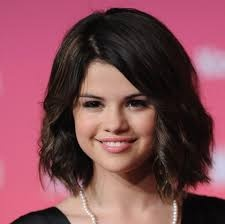

In [33]:
img2 = '/content/drive/MyDrive/Mask data (1)/Mask_test/without_mask/11.jpg'
img2_read = imread(img2)
img2_read

In [34]:
res2 = resize(img2_read,(1,150,150,3))
pred2 = model.predict(res2)
pred2

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


array([[0.8931365 , 0.10686348]], dtype=float32)

In [35]:
pred_class = np.argmax(pred2,axis=1)
pred_class

array([0])

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [252, 254, 249],
        [252, 255, 248],
        [253, 255, 249]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [253, 255, 250],
        [252, 254, 249],
        [252, 255, 248]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 251],
        [254, 255, 251],
        [254, 255, 251]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [217,  15,  63],
        [211,  18,  63],
        [207,  20,  63]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [211,  13,  62],
        [205,  15,  59],
        [201,  16,  58]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [209,  13,  61],
        [202,  12,  56],
        [197,  12,  54]]], shape=(428, 320, 3), dtype=uint8)
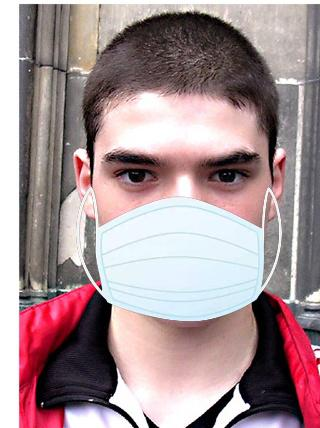

In [40]:
img = '/content/drive/MyDrive/Mask data (1)/Mask_test/with_mask/148-with-mask.jpg'
img_read = imread(img)
img_read

In [42]:
res = resize(img_read,(1,150,150,3))
pred = model.predict(res)
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step


array([[0.19866993, 0.8013301 ]], dtype=float32)

In [44]:
predicted_class = np.argmax(pred,axis=1)
print(predicted_class)

[1]


array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[254, 254, 254],
        [255, 255, 255],
        [252, 252, 252],
        ...,
        [213, 213, 213],
        [213, 213, 213],
        [213, 213, 213]],

       [[255, 255, 255],
        [255, 255, 255],
        [252, 252, 252],
        ...,
        [253, 253, 253],
        [253, 253, 253],
        [253, 253, 253]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]]], shape=(428, 320, 3), dtype=uint8)
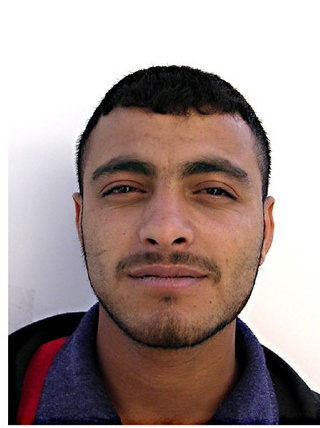

In [45]:
img3 = '/content/drive/MyDrive/Mask data (1)/Mask_test/without_mask/417.jpg'
img_read3 = imread(img3)
img_read3

In [46]:
res3 = resize(img_read3,(1,150,150,3))
pred3 = model.predict(res3)
pred3

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step


array([[0.979385  , 0.02061498]], dtype=float32)

In [47]:
pred_class1 = np.argmax(pred3,axis=1)
print(pred_class1)

[0]


In [48]:
model.evaluate(xtest, ytest)

4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 1.0000 - loss: 0.0040


[0.003955071792006493, 1.0]

array([[[214, 205, 210],
        [214, 205, 210],
        [214, 205, 210],
        ...,
        [200, 194, 194],
        [198, 192, 192],
        [197, 191, 191]],

       [[214, 205, 210],
        [214, 205, 210],
        [214, 205, 210],
        ...,
        [200, 194, 194],
        [198, 192, 192],
        [197, 191, 191]],

       [[214, 205, 210],
        [214, 205, 210],
        [214, 205, 210],
        ...,
        [200, 194, 194],
        [198, 192, 192],
        [197, 191, 191]],

       ...,

       [[201, 195, 197],
        [201, 195, 197],
        [201, 195, 197],
        ...,
        [190, 185, 182],
        [188, 183, 180],
        [188, 183, 180]],

       [[201, 195, 197],
        [201, 195, 197],
        [201, 195, 197],
        ...,
        [189, 184, 181],
        [188, 183, 180],
        [187, 182, 179]],

       [[201, 195, 197],
        [201, 195, 197],
        [201, 195, 197],
        ...,
        [189, 184, 181],
        [188, 183, 180],
        [187, 182, 179]]], shape=(447, 447, 3), dtype=uint8)
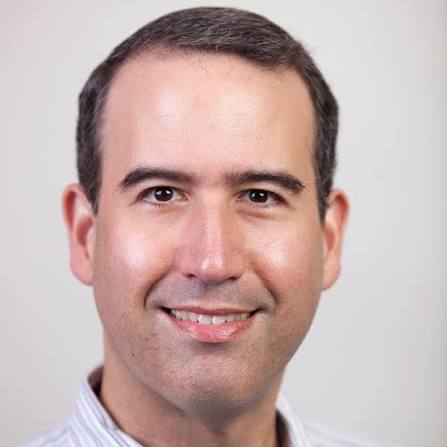

In [49]:
img4 = '/content/without_mask.jpg'
img_read4 = imread(img4)
img_read4

In [50]:
res4 = resize(img_read4,(1,150,150,3))
pred4 = model.predict(res4)
pred4

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step


array([[0.94965386, 0.05034611]], dtype=float32)

In [51]:
pred_class2 = np.argmax(pred4,axis=1)
print(pred_class2)

[0]
